# 10. Figure 3, tunable

Six panels, one per thematic group. Countries in the sample are filled by the sign of
their TVR on that group and carry a dot coloured by their OSI on it. Everything that can
be adjusted sits in the Settings cell, so the rest of the notebook is left alone.

Two things differ from the 2025 version, both deliberate.

* **The base map is Natural Earth 1:50m Admin 0 Countries**, the same file Figure 2 uses.
  The original used `world-administrative-boundaries.shp` plus cartopy's own land and
  coastline features. Natural Earth is public domain, which is what the editor's query
  about third-party rights in Figures 2 and 3 needs answering with.
* **The dot threshold is a setting, not 0.73.** The published figure split the dots at
  0.73, the mean group-level OSI of the earlier sample. On the rebuilt sample that mean
  is 0.833, and splitting at 0.73 turns 526 of the 600 dots green. `OSI_CUT` defaults to
  the rebuilt mean and prints the resulting split.

In [1]:
import sys, os
sys.path.insert(0, os.path.join(os.getcwd(), 'src'))  # the modules the notebooks import live in src/


In [2]:
import os, sys, warnings
warnings.filterwarnings('ignore')
sys.path.insert(0, '.')
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import config as cfg, figures as fg, regress as rg

In [3]:
OUT = 'output/figures'
os.makedirs(OUT, exist_ok=True)

# Natural Earth 1:50m Admin 0 Countries. Public domain, no permission required
# (naturalearthdata.com/about/terms-of-use).
BASEMAP = 'assets/naturalearth/ne_50m_admin_0_countries.shp'

idx = pd.read_csv('output/indices_2022_by_country.csv', index_col=0)
world = gpd.read_file(BASEMAP)
world = world[world.geometry.notna()].copy()
world['iso'] = world.ISO_A3.where(world.ISO_A3 != '-99', world.ADM0_A3)

_cw = rg.crosswalk()
ISO3 = {c: _cw.get(c) for c in idx.index}
print('countries with no polygon:', [c for c, v in ISO3.items()
                                     if v is None or v not in set(world.iso)] or 'none')

# One row per sample country, dissolved, with a point for the dot.
_iso_to_name = {v: k for k, v in ISO3.items() if v}
geo = world[world.iso.isin(_iso_to_name)].copy()
geo['country'] = geo.iso.map(_iso_to_name)
geo = geo.dissolve(by='country')
_pt = geo.geometry.representative_point()
geo['lon'], geo['lat'] = _pt.x, _pt.y
COUNTRIES = [c for c in idx.index if c in geo.index]

GROUPS = [f'G{i}' for i in range(1, 7)]
print(f'{len(COUNTRIES)} countries on the map')
_osi = idx[[g + '_OSI' for g in GROUPS]]
print(f'group-level OSI: mean {_osi.values.mean():.3f}, median {np.median(_osi.values):.3f}')

countries with no polygon: none
100 countries on the map
group-level OSI: mean 0.833, median 0.852


## Settings

In [4]:
# ---- base map ----------------------------------------------------------------------
LAND         = '#F2F2F2'      # countries that are not in the sample
OCEAN        = '#FFFFFF'      # the panel background
BORDER       = '#FFFFFF'      # the line between countries
BORDER_WIDTH = 0.3
COAST_SHOW   = True           # a thin outline round the land, the cartopy COASTLINE
COAST        = '#BFBFBF'      # of the published version
COAST_WIDTH  = 0.2
MAP_XLIM, MAP_YLIM = (-180, 180), (-60, 85)

# ---- the TVR fill --------------------------------------------------------------------
# Two bins split at zero, which is what the published figure uses. The 2025 notebook
# defined four (<log 0.5, log 0.5-0, 0-log 2, >log 2) but printed only these two.
TVR_CUT   = 0.0
TVR_OVER  = '#FCDBC7'         # TVR above the cut, over-discussed online
TVR_UNDER = '#D1E5F0'         # TVR below the cut, under-discussed online

# ---- the OSI dots --------------------------------------------------------------------
OSI_CUT   = 0.833             # the rebuilt sample's mean group-level OSI.
                              # The published figure used 0.73, the earlier sample's mean.
DOT_HIGH  = '#95C090'         # OSI above the cut
DOT_LOW   = '#E48FB7'         # OSI below the cut
DOT_SIZE  = 50
DOT_EDGE  = 'white'
DOT_LW    = 0.6
DOT_ALPHA = 1.0

# ---- type ----------------------------------------------------------------------------
TITLE_FONT = 'Times New Roman'
TITLE_SIZE = 18
TITLE_BOLD = True
GROUP_TITLES = {g: f'{g}: {cfg.GROUP_NAMES[g]}' for g in GROUPS}   # edit any of these

PANEL_LETTERS = True          # a-f in the top-left corner of each panel, as in the published figure
                              # panel, so the caption can define them one by one
PANEL_LETTER_SIZE = 16

ANNOT_SHOW = True             # the "Mean: TVR / OSI" block in the corner
ANNOT_XY   = (0.02, 0.34)     # axes fraction
ANNOT_FONT = 'Times New Roman'
ANNOT_SIZE = 16

# ---- legend and layout -----------------------------------------------------------------
LEGEND_SHOW = True
LEGEND_FONT = 'Times New Roman'
LEGEND_SIZE = 13
NCOLS   = 2                   # 2 reproduces the published layout, 1 gives a tall column
FIGSIZE = (18, 11)
DPI     = 300

## The panels

In [5]:
_coast_cache = {}

def coastline():
    if COAST_SHOW and 'b' not in _coast_cache:
        _coast_cache['b'] = world.dissolve().boundary
    return _coast_cache.get('b')


def panel_frame(g):
    """One row per sample country with the fill colour and dot colour for group g."""
    d = pd.DataFrame({
        'tvr': idx.loc[COUNTRIES, f'{g}_TVR'],
        'osi': idx.loc[COUNTRIES, f'{g}_OSI'],
        'lon': geo.loc[COUNTRIES, 'lon'],
        'lat': geo.loc[COUNTRIES, 'lat'],
    })
    d['fill_color'] = np.where(d.tvr > TVR_CUT, TVR_OVER, TVR_UNDER)
    d['dot_color'] = np.where(d.osi > OSI_CUT, DOT_HIGH, DOT_LOW)
    return d


def draw_panel(ax, g):
    d = panel_frame(g)
    ax.set_facecolor(OCEAN)
    world.plot(ax=ax, color=LAND, edgecolor=BORDER, linewidth=BORDER_WIDTH, zorder=1)
    geo.loc[d.index].plot(ax=ax, color=d['fill_color'].to_numpy(), edgecolor=BORDER,
                          linewidth=BORDER_WIDTH, zorder=2)
    if COAST_SHOW:
        coastline().plot(ax=ax, color=COAST, linewidth=COAST_WIDTH, zorder=3)
    ax.scatter(d.lon, d.lat, s=DOT_SIZE, c=d['dot_color'].to_numpy(), edgecolor=DOT_EDGE,
               linewidth=DOT_LW, alpha=DOT_ALPHA, zorder=5)

    if ANNOT_SHOW:
        txt = 'Mean:\nTVR = {:.3f}\nOSI =  {:.3f}'.format(d.tvr.mean(), d.osi.mean())
        ax.text(*ANNOT_XY, txt, transform=ax.transAxes, va='top', ha='left',
                fontsize=ANNOT_SIZE, fontfamily=ANNOT_FONT, zorder=6)

    if PANEL_LETTERS:
        ax.text(0.004, 0.995, 'abcdef'[GROUPS.index(g)], transform=ax.transAxes,
                ha='left', va='top', fontsize=PANEL_LETTER_SIZE, fontweight='bold',
                zorder=6)
    ax.set_title(GROUP_TITLES[g], fontsize=TITLE_SIZE, fontfamily=TITLE_FONT,
                 fontweight='bold' if TITLE_BOLD else 'normal')
    ax.set_xlim(*MAP_XLIM); ax.set_ylim(*MAP_YLIM)
    # not ax.axis('off'): that hides the background patch and the ocean colour with it.
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_facecolor(OCEAN)
    for s in ax.spines.values():
        s.set_visible(False)
    return d


def draw_legend(fig):
    tvr = [Patch(facecolor=TVR_OVER, edgecolor='#999999', lw=0.4,
                 label=f'Over-discussed (>{TVR_CUT:g})'),
           Patch(facecolor=TVR_UNDER, edgecolor='#999999', lw=0.4,
                 label=f'Under-discussed (<{TVR_CUT:g})')]
    osi = [Line2D([], [], marker='o', ls='none', markerfacecolor=DOT_HIGH,
                  markeredgecolor=DOT_EDGE, markersize=11,
                  label=f'Higher support (>{OSI_CUT:g})'),
           Line2D([], [], marker='o', ls='none', markerfacecolor=DOT_LOW,
                  markeredgecolor=DOT_EDGE, markersize=11,
                  label=f'Lower support (<{OSI_CUT:g})')]
    kw = dict(frameon=False, ncol=2, prop={'family': LEGEND_FONT, 'size': LEGEND_SIZE},
              title_fontproperties={'family': LEGEND_FONT, 'size': LEGEND_SIZE,
                                    'weight': 'bold'})
    l1 = fig.legend(handles=tvr, title='Topic Visibility Ratio (TVR):',
                    loc='lower left', bbox_to_anchor=(0.04, 0.005), **kw)
    fig.add_artist(l1)
    fig.legend(handles=osi, title='Online Stance Index (OSI):',
               loc='lower left', bbox_to_anchor=(0.52, 0.005), **kw)

## The figure

saved output/figures/Figure3_groups.png


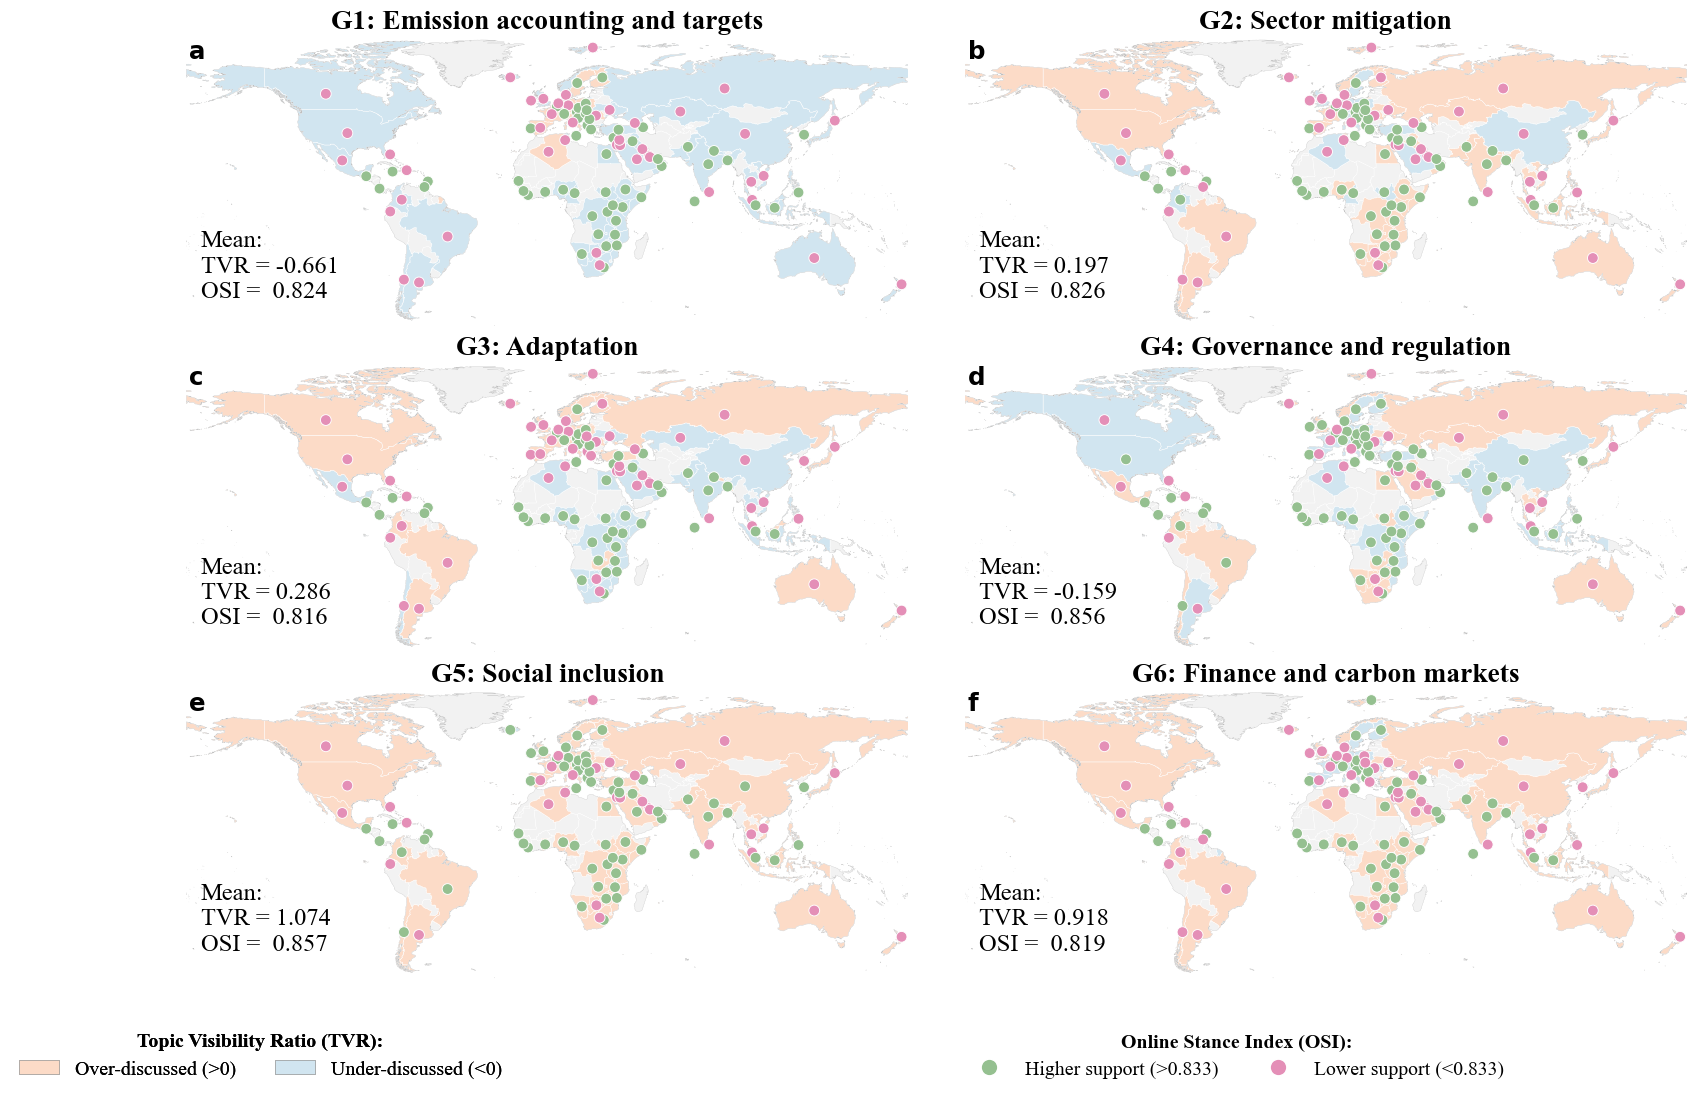

In [6]:
def save(fig, name):
    for ext in ('png', 'pdf'):
        fig.savefig(f'{OUT}/{name}.{ext}', dpi=DPI, bbox_inches='tight',
                    facecolor=OCEAN)
    print('saved', f'{OUT}/{name}.png')


nrows = int(np.ceil(6 / NCOLS))
fig, axes = plt.subplots(nrows, NCOLS, figsize=FIGSIZE, dpi=110)
frames = {g: draw_panel(ax, g) for ax, g in zip(np.ravel(axes), GROUPS)}
for ax in np.ravel(axes)[6:]:
    fig.delaxes(ax)
if LEGEND_SHOW:
    draw_legend(fig)
fig.subplots_adjust(bottom=0.10, wspace=0.03, hspace=0.12)
save(fig, 'Figure3_groups'); plt.show()

## The numbers behind the panels

In [7]:
rows = []
for g in GROUPS:
    d = frames[g]
    rows.append({'group': GROUP_TITLES[g],
                 'TVR_mean': round(d.tvr.mean(), 3),
                 'OSI_mean': round(d.osi.mean(), 3),
                 'over_discussed': int((d.tvr > TVR_CUT).sum()),
                 'under_discussed': int((d.tvr <= TVR_CUT).sum()),
                 'higher_support': int((d.osi > OSI_CUT).sum()),
                 'lower_support': int((d.osi <= OSI_CUT).sum())})
summary = pd.DataFrame(rows)
print(summary.to_string(index=False))

src = pd.DataFrame({'country': COUNTRIES})
for g in GROUPS:
    src[f'{g}_TVR'] = idx.loc[COUNTRIES, f'{g}_TVR'].round(4).to_numpy()
    src[f'{g}_OSI'] = idx.loc[COUNTRIES, f'{g}_OSI'].round(4).to_numpy()
src.to_csv('output/SI/Figure3_source_data.csv', index=False)
summary.to_csv('output/SI/Figure3_group_summary.csv', index=False)
print('\nwrote output/SI/Figure3_source_data.csv and Figure3_group_summary.csv')

                              group  TVR_mean  OSI_mean  over_discussed  under_discussed  higher_support  lower_support
G1: Emission accounting and targets    -0.661     0.824              18               82              56             44
              G2: Sector mitigation     0.197     0.826              76               24              55             45
                     G3: Adaptation     0.286     0.816              48               52              49             51
      G4: Governance and regulation    -0.159     0.856              43               57              68             32
               G5: Social inclusion     1.074     0.857              99                1              67             33
     G6: Finance and carbon markets     0.918     0.819              78               22              51             49

wrote output/SI/Figure3_source_data.csv and Figure3_group_summary.csv
